[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/calculus-and-optimization/gradient-descent-and-its-variants/notebook.ipynb)

# Gradient Descent and its Variants: hands-on

This notebook goes with the [topic README](README.md). You will run gradient descent on one and two variables, watch the three learning-rate behaviours and the limit $2/\lambda_{\max}$, see a narrow valley zig-zag and feature scaling cure it, try the stopping rules, meet local minima and saddles, fit a line by batch gradient descent and by the normal equations, and then add noise (SGD and mini-batches), schedules, momentum, AdaGrad, RMSProp, and Adam. It ends with a logistic regression, a small optimiser class, and a gradient check. Everything uses NumPy and Matplotlib and invented data, so it runs in a minute on a CPU.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 50
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
np.set_printoptions(precision=4, suppress=True)
ORANGE, BLUE, GREEN = "tab:orange", "tab:blue", "tab:green"


def gradient_descent(grad, x0, eta, steps):
    # Plain gradient descent. Returns every iterate, one row per step.
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    for _ in range(steps):
        x = x - eta * grad(x)
        path.append(x.copy())
    return np.array(path)


def num_grad(func, p, h=1e-5):
    # Centered finite-difference gradient, one coordinate at a time.
    p = np.asarray(p, dtype=float)
    g = np.zeros_like(p)
    for i in range(len(p)):
        e = np.zeros_like(p)
        e[i] = h
        g[i] = (func(p + e) - func(p - e)) / (2 * h)
    return g

## 1. One variable

Minimise $f(x) = (x-3)^2 + 1$ with $f'(x) = 2(x-3)$. The update is $x \leftarrow x - \eta f'(x)$. With $\eta = 0.1$ the distance to the minimum shrinks by a factor $1 - 2\eta = 0.8$ each step, which the table confirms.

step      x       f(x)    distance to 3
   0   0.0000   10.0000    3.0000
   1   0.6000    6.7600    2.4000
   2   1.0800    4.6864    1.9200
   3   1.4640    3.3593    1.5360
   4   1.7712    2.5099    1.2288
   5   2.0170    1.9664    0.9830
   6   2.2136    1.6185    0.7864
   7   2.3709    1.3958    0.6291
   8   2.4967    1.2533    0.5033
ratio of successive distances is 0.8: True


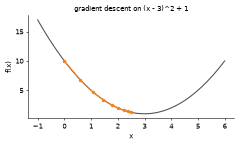

In [2]:
f1 = lambda x: (x - 3) ** 2 + 1
g1 = lambda x: 2 * (x - 3)
p1 = gradient_descent(g1, [0.0], 0.1, 8)[:, 0]
print("step      x       f(x)    distance to 3")
for k, x in enumerate(p1):
    print(f"{k:4d} {x:8.4f} {f1(x):9.4f} {abs(x - 3):9.4f}")
print("ratio of successive distances is 0.8:", np.allclose(np.abs(p1[1:] - 3) / np.abs(p1[:-1] - 3), 0.8))

xx = np.linspace(-1, 6, 200)
plt.figure(figsize=(5, 3))
plt.plot(xx, f1(xx), color="0.3")
plt.plot(p1, f1(p1), "o-", color=ORANGE, ms=4)
plt.title("gradient descent on (x - 3)^2 + 1"); plt.xlabel("x"); plt.ylabel("f(x)")
plt.tight_layout()

Each step is shorter than the one before, even though $\eta$ never changed: the gradient itself shrinks as we approach the bottom.

## 2. Three learning rates

For $f(x) = (x-3)^2 + 1$ the error is multiplied by $1 - 2\eta$ each step. Three values show the three behaviours: too small (factor near $1$), good, and too large (factor below $-1$, so the error grows and flips sign).

eta =  0.02: x after 12 steps =     1.162
eta =  0.30: x after 12 steps =     3.000
eta =  1.08: x after 12 steps =   -14.808


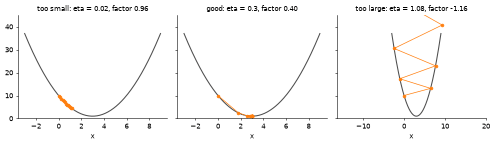

In [3]:
etas = [0.02, 0.3, 1.08]
names = ["too small", "good", "too large"]
fig, axs = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, eta, nm in zip(axs, etas, names):
    p = gradient_descent(g1, [0.0], eta, 12)[:, 0]
    ax.plot(xx := np.linspace(-3, 9, 200), f1(xx), color="0.3")
    ax.plot(p, f1(p), "o-", color=ORANGE, ms=4, lw=1)
    ax.set_title(f"{nm}: eta = {eta}, factor {1 - 2 * eta:.2f}"); ax.set_xlabel("x"); ax.set_ylim(0, 45)
    print(f"eta = {eta:5.2f}: x after 12 steps = {p[-1]:9.3f}")
fig.tight_layout()

A factor with $|1-2\eta|<1$ converges. At $\eta = 1$ the factor is $-1$ and the iterate bounces between two points forever, and anything above $\eta = 1 = 2/\lambda$ (here $\lambda = f'' = 2$) diverges.

In [4]:
for eta in [0.5, 0.9, 1.0, 1.1]:
    p = gradient_descent(g1, [0.0], eta, 5)[:, 0]
    print(f"eta = {eta}: {np.round(p, 3)}")

eta = 0.5: [0. 3. 3. 3. 3. 3.]
eta = 0.9: [0.    5.4   1.08  4.536 1.771 3.983]
eta = 1.0: [0. 6. 0. 6. 0. 6.]
eta = 1.1: [ 0.     6.6   -1.32   8.184 -3.221 10.465]


## 3. Two dimensions: round bowl, narrow valley

On $f(\mathbf{x}) = \tfrac12 \mathbf{x}^\top H \mathbf{x}$ with diagonal $H$ the gradient is $H\mathbf{x}$. First a mild bowl with $H = \operatorname{diag}(1, 4)$, then a valley with $H = \operatorname{diag}(1, 50)$ (condition number $\kappa = 50$). The first three steps of the mild bowl match the table in the README.

[[4.    1.   ]
 [3.2   0.2  ]
 [2.56  0.04 ]
 [2.048 0.008]]


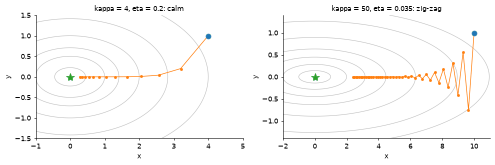

In [5]:
def quad(h):
    h = np.asarray(h, dtype=float)
    return (lambda p: 0.5 * np.tensordot(h, np.asarray(p) ** 2, axes=(0, 0))), (lambda p: h * p)

f_mild, g_mild = quad([1, 4])
f_vall, g_vall = quad([1, 50])
print(gradient_descent(g_mild, [4, 1], 0.2, 3))

def contour_path(ax, fun, path, xlim, ylim, levels):
    X, Y = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
    ax.contour(X, Y, fun(np.array([X, Y])), levels=levels, colors="0.75", linewidths=0.8)
    ax.plot(path[:, 0], path[:, 1], "o-", color=ORANGE, ms=3, lw=1)
    ax.plot(*path[0], "o", color=BLUE, ms=7); ax.plot(0, 0, "*", color=GREEN, ms=12)
    ax.set_xlabel("x"); ax.set_ylabel("y")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
contour_path(axs[0], f_mild, gradient_descent(g_mild, [4, 1], 0.2, 12), (-1, 5), (-1.5, 1.5), [0.1, 0.5, 1, 2, 4, 8])
axs[0].set_title("kappa = 4, eta = 0.2: calm")
contour_path(axs[1], f_vall, gradient_descent(g_vall, [10, 1], 0.035, 40), (-2, 11), (-1.4, 1.4), [0.5, 2, 5, 10, 20, 40, 60])
axs[1].set_title("kappa = 50, eta = 0.035: zig-zag")
fig.tight_layout()

In the valley the safe step is capped by the steep direction ($\eta < 2/50 = 0.04$), so the gentle direction advances by only $3.5\%$ of the remaining distance per step. Roughly, the number of steps grows in proportion to $\kappa$.

## 4. The limit 2 / lambda_max

On $H = \operatorname{diag}(1, 4)$ the largest curvature is $\lambda_{\max} = 4$, so the limit is $\eta < 0.5$. We run $50$ steps for many learning rates and plot the final distance from the minimum on a log scale: it falls until $\eta = 2/(\lambda_{\max} + \lambda_{\min}) = 0.4$, the best constant step, then rises. At exactly $0.5$ the steep direction bounces forever (the distance stays at $1$), and beyond it the iterate explodes.

eta = 0.45: distance after 50 steps = 1.43e-05
eta = 0.5: distance after 50 steps = 1
eta = 0.55: distance after 50 steps = 9.1e+03


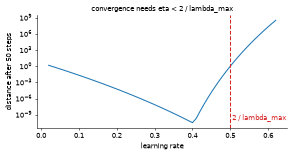

In [6]:
etas = np.linspace(0.02, 0.62, 61)
final = [np.linalg.norm(gradient_descent(g_mild, [4, 1], e, 50)[-1]) for e in etas]
plt.figure(figsize=(6, 3.2))
plt.semilogy(etas, np.maximum(final, 1e-16), color=BLUE)
plt.axvline(0.5, color="tab:red", ls="--"); plt.text(0.505, 1e-10, "2 / lambda_max", color="tab:red")
plt.xlabel("learning rate"); plt.ylabel("distance after 50 steps"); plt.title("convergence needs eta < 2 / lambda_max")
plt.tight_layout()
for e in [0.45, 0.5, 0.55]:
    print(f"eta = {e}: distance after 50 steps = {np.linalg.norm(gradient_descent(g_mild, [4, 1], e, 50)[-1]):.3g}")

## 5. Feature scaling

Invented data: a score against hours studied, $\text{score} \approx 2.5\cdot\text{hours} + 4$ plus noise. The model is $\hat y = wx + b$ with the average squared-error loss, whose Hessian is $X^\top X / n$. With raw hours ($0$ to $10$) the valley is long and narrow. After standardising the feature (subtract the mean, divide by the spread) the contours are round.

In [7]:
rng = np.random.default_rng(0)
n = 100
hours = rng.uniform(0, 10, n)
score = 2.5 * hours + 4 + rng.normal(0, 0.8, n)
X_raw = np.column_stack([hours, np.ones(n)])
X_std = np.column_stack([(hours - hours.mean()) / hours.std(), np.ones(n)])
mse = lambda w, X: 0.5 * np.mean((X @ w - score) ** 2)
grad_mse = lambda w, X, y: X.T @ (X @ w - y) / len(y)

for name, X in [("raw", X_raw), ("standardised", X_std)]:
    lam = np.linalg.eigvalsh(X.T @ X / n)
    print(f"{name:13s} eigenvalues {lam}, kappa = {lam[-1] / lam[0]:.1f}, safe eta < {2 / lam[-1]:.4f}")

def steps_to_tolerance(X, eta, tol=1e-6, cap=20000):
    w_star = np.linalg.lstsq(X, score, rcond=None)[0]
    w = np.zeros(2)
    for k in range(cap):
        if mse(w, X) - mse(w_star, X) < tol:
            return k
        w = w - eta * grad_mse(w, X, score)
    return cap

print("raw, eta = 0.04       :", steps_to_tolerance(X_raw, 0.04), "steps")
print("standardised, eta = 1 :", steps_to_tolerance(X_std, 1.0), "step")

raw           eigenvalues [ 0.2296 40.0196], kappa = 174.3, safe eta < 0.0500
standardised  eigenvalues [1. 1.], kappa = 1.0, safe eta < 2.0000
raw, eta = 0.04       : 771 steps
standardised, eta = 1 : 1 step


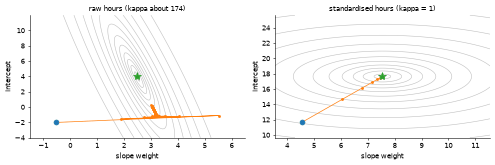

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (X, eta, steps, ttl) in zip(axs, [(X_raw, 0.04, 40, "raw hours (kappa about 174)"), (X_std, 0.5, 8, "standardised hours (kappa = 1)")]):
    ws = np.linalg.lstsq(X, score, rcond=None)[0]
    a = np.linspace(ws[0] - 4, ws[0] + 4, 150); b = np.linspace(ws[1] - 8, ws[1] + 8, 150)
    A, Bm = np.meshgrid(a, b)
    L = 0.5 * np.mean((X[:, 0, None, None] * A + X[:, 1, None, None] * Bm - score[:, None, None]) ** 2, axis=0)
    ax.contour(A, Bm, L, levels=np.geomspace(0.35, 60, 12), colors="0.75", linewidths=0.8)
    w = np.array([ws[0] - 3.0, ws[1] - 6.0]); path = [w.copy()]
    for _ in range(steps):
        w = w - eta * grad_mse(w, X, score); path.append(w.copy())
    path = np.array(path)
    ax.plot(path[:, 0], path[:, 1], "o-", color=ORANGE, ms=3, lw=1); ax.plot(*path[0], "o", color=BLUE, ms=7); ax.plot(*ws, "*", color=GREEN, ms=12)
    ax.set_title(ttl); ax.set_xlabel("slope weight"); ax.set_ylabel("intercept")
fig.tight_layout()

The raw problem creeps along a ridge while the standardised one heads straight for the answer. The standardised weights describe the same line: the slope is the original slope times the spread of the hours.

## 6. Stopping rules

Three common rules: the gradient norm is below a tolerance, the loss changes by less than a tolerance, or we hit an iteration cap. This function stops at the first rule that fires and says which one.

In [9]:
def descend_with_stopping(f, grad, x0, eta, tol_grad=1e-4, tol_loss=1e-12, max_steps=500):
    x = np.array(x0, dtype=float)
    for k in range(1, max_steps + 1):
        g = grad(x)
        if np.linalg.norm(g) < tol_grad:
            return x, k, "gradient norm small"
        x_new = x - eta * g
        if abs(f(x_new) - f(x)) < tol_loss:
            return x_new, k, "loss barely changed"
        x = x_new
    return x, max_steps, "iteration cap"

for eta in [0.2, 0.01, 0.55]:
    x, k, why = descend_with_stopping(f_mild, g_mild, [4, 1], eta)
    print(f"eta = {eta:4}: stopped after {k:3d} steps because: {why}; f = {f_mild(x):.3g}")

eta =  0.2: stopped after  49 steps because: gradient norm small; f = 3.98e-09
eta = 0.01: stopped after 500 steps because: iteration cap; f = 0.000345
eta = 0.55: stopped after 500 steps because: iteration cap; f = 3.04e+79


With a good step the gradient rule fires. With a tiny step the iteration cap protects us. With a step above the limit the loss never settles, so only the cap stops it, and the final value is huge. A tiny change in loss does not always mean we are done: always look at the gradient norm too.

## 7. Local minima, saddles, and plateaus

$f(x) = x^4 - 3x^2 + x$ has two valleys, and the starting point decides which one we reach. The function $x^2 - y^2$ has a saddle at the origin, and a path that starts exactly on the ridge ($y = 0$) walks into it. A path that starts a hair off the ridge slides away. Finally $x^4$ has a very flat bottom, where the gradient is tiny long before we are at the minimum.

In [10]:
fd = lambda x: x ** 4 - 3 * x ** 2 + x
gd_ = lambda x: 4 * x ** 3 - 6 * x + 1
for x0 in [-2.0, -0.2, 0.5, 1.6]:
    x_end = gradient_descent(gd_, [x0], 0.02, 400)[-1, 0]
    print(f"start {x0:5.1f} -> ends at x = {x_end:6.3f}, f = {fd(x_end):6.3f}")

saddle_grad = lambda p: np.array([2 * p[0], -2 * p[1]])
on_ridge = gradient_descent(saddle_grad, [1.5, 0.0], 0.1, 60)
off_ridge = gradient_descent(saddle_grad, [1.5, 1e-6], 0.1, 60)
print("start on the ridge, after 60 steps:   ", on_ridge[-1])
print("start 1e-6 off the ridge, after 60 steps:", off_ridge[-1])

# a plateau: f = x^4 has gradient 4 x^3, tiny near 0
p = gradient_descent(lambda x: 4 * x ** 3, [0.5], 0.1, 2000)[:, 0]
print("x^4 from 0.5: x after 10, 100, 1000, 2000 steps:", p[[10, 100, 1000, 2000]])

start  -2.0 -> ends at x = -1.301, f = -3.514
start  -0.2 -> ends at x = -1.301, f = -3.514
start   0.5 -> ends at x =  1.131, f = -1.070
start   1.6 -> ends at x =  1.131, f = -1.070
start on the ridge, after 60 steps:    [0. 0.]
start 1e-6 off the ridge, after 60 steps: [0.     0.0563]
x^4 from 0.5: x after 10, 100, 1000, 2000 steps: [0.2802 0.1079 0.0352 0.0249]


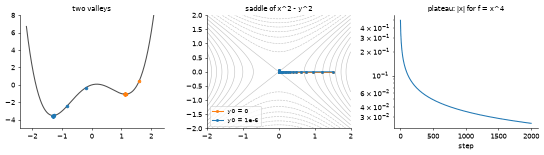

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
xx = np.linspace(-2.2, 2.2, 300)
axs[0].plot(xx, fd(xx), color="0.3")
for x0, c in [(-0.2, BLUE), (1.6, ORANGE)]:
    pp = gradient_descent(gd_, [x0], 0.02, 200)[::10, 0]
    axs[0].plot(pp, fd(pp), "o", color=c, ms=4)
axs[0].set_title("two valleys"); axs[0].set_ylim(-5, 8)
X, Y = np.meshgrid(np.linspace(-2, 2, 200), np.linspace(-2, 2, 200))
axs[1].contour(X, Y, X ** 2 - Y ** 2, levels=np.linspace(-3.5, 3.5, 15), colors="0.75", linewidths=0.8)
axs[1].plot(on_ridge[:, 0], on_ridge[:, 1], "o-", color=ORANGE, ms=3, label="y0 = 0")
axs[1].plot(off_ridge[:, 0], off_ridge[:, 1], "o-", color=BLUE, ms=3, label="y0 = 1e-6")
axs[1].legend(fontsize=8, loc="lower left"); axs[1].set_title("saddle of x^2 - y^2"); axs[1].set_ylim(-2, 2)
axs[2].semilogy(np.abs(p) + 1e-12, color=BLUE); axs[2].set_xlabel("step"); axs[2].set_title("plateau: |x| for f = x^4")
fig.tight_layout()

The saddle trap is exact only in exact arithmetic with a perfectly placed start. Any tiny sideways push (rounding, or the noise of SGD) lets the path escape, though it may spend many steps near the saddle first.

## 8. Linear regression: batch gradient descent versus the normal equations

The normal equations $X^\top X\,\mathbf{w} = X^\top\mathbf{y}$ give the exact least-squares answer in one solve. Batch gradient descent reaches the same point by repeated small steps. On standardised features it needs a handful of steps. On raw features it is slow, because $\kappa \approx 174$.

normal equations: [ 7.5458 17.644 ]   lstsq: [ 7.5458 17.644 ]
standardised GD matches normal equations: True
raw GD after 200 steps, weights: [2.5689 3.4293]  (the normal-equation weights on raw inputs are [2.4895 3.994 ] )


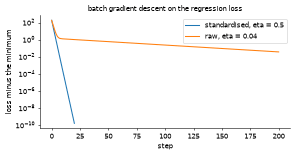

In [12]:
w_normal = np.linalg.solve(X_std.T @ X_std, X_std.T @ score)
print("normal equations:", w_normal, "  lstsq:", np.linalg.lstsq(X_std, score, rcond=None)[0])

def batch_gd_curve(X, eta, steps):
    w = np.zeros(2); losses = [mse(w, X)]
    for _ in range(steps):
        w = w - eta * grad_mse(w, X, score); losses.append(mse(w, X))
    return w, np.array(losses)

w_std, curve_std = batch_gd_curve(X_std, 0.5, 20)
w_raw, curve_raw = batch_gd_curve(X_raw, 0.04, 200)
best = mse(w_normal, X_std)
print("standardised GD matches normal equations:", np.allclose(w_std, w_normal, atol=1e-4))
print("raw GD after 200 steps, weights:", w_raw, " (the normal-equation weights on raw inputs are", np.linalg.lstsq(X_raw, score, rcond=None)[0], ")")
plt.figure(figsize=(6, 3.2))
plt.semilogy(curve_std - best + 1e-12, label="standardised, eta = 0.5")
plt.semilogy(curve_raw - best + 1e-12, label="raw, eta = 0.04")
plt.xlabel("step"); plt.ylabel("loss minus the minimum"); plt.legend(); plt.title("batch gradient descent on the regression loss")
plt.tight_layout()

When $d$ (the number of features) is small the normal equations win: one solve. Gradient descent earns its keep when $d$ or $n$ is so large that forming $X^\top X$ is too costly, or when the loss has no closed form, which is the case for almost every deep-learning loss.

## 9. SGD and mini-batch paths

The same standardised regression, trained with three batch sizes: the full batch ($100$), mini-batches of $10$, and one example per step. Each update uses the average gradient of its batch. Shuffling happens at the start of every epoch.

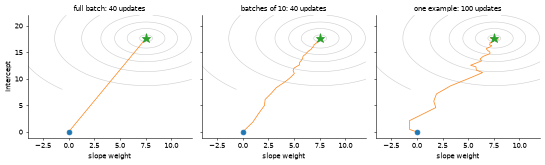

In [13]:
def minibatch_run(X, batch, eta, epochs, seed=1, w0=(0.0, 0.0)):
    r = np.random.default_rng(seed)
    w = np.array(w0, dtype=float); path = [w.copy()]
    for _ in range(epochs):
        idx = r.permutation(n)
        for s in range(0, n, batch):
            b = idx[s:s + batch]
            w = w - eta * grad_mse(w, X[b], score[b])
            path.append(w.copy())
    return np.array(path)

w_star = np.linalg.lstsq(X_std, score, rcond=None)[0]
a = np.linspace(-4, 12, 150); b_ = np.linspace(8, 22, 150)
A, Bm = np.meshgrid(a, b_)
Lgrid = 0.5 * np.mean((X_std[:, 0, None, None] * A + X_std[:, 1, None, None] * Bm - score[:, None, None]) ** 2, axis=0)
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
for ax, (B, eta, ep, nm) in zip(axs, [(100, 0.1, 40, "full batch"), (10, 0.1, 4, "batches of 10"), (1, 0.1, 1, "one example")]):
    p = minibatch_run(X_std, B, eta, ep)
    ax.contour(A, Bm, Lgrid, levels=[0.5, 2, 5, 10, 20, 40, 80, 120, 160], colors="0.8", linewidths=0.8)
    ax.plot(p[:, 0], p[:, 1], "-", color=ORANGE, lw=1); ax.plot(*p[0], "o", color=BLUE, ms=7); ax.plot(*w_star, "*", color=GREEN, ms=13)
    ax.set_title(f"{nm}: {len(p) - 1} updates"); ax.set_xlabel("slope weight")
axs[0].set_ylabel("intercept")
fig.tight_layout()

The path of single-example SGD is jagged because each example pulls the weights toward its own best line, but on average the pull points downhill. Mini-batches smooth the path at a cost of $B$ times more work per update.

## 10. Batch size and the variance of the gradient

At a fixed point $\mathbf{w}$ we draw many random batches of size $B$ and look at the spread of the batch gradient. Its average equals the full gradient (unbiased), and its standard deviation falls like $1/\sqrt{B}$.

full gradient (first coordinate): -7.546
B =   1: mean of estimates   -7.379, standard deviation 17.571, std * sqrt(B) = 17.571
B =   2: mean of estimates   -7.941, standard deviation 12.304, std * sqrt(B) = 17.400
B =   4: mean of estimates   -7.335, standard deviation  8.776, std * sqrt(B) = 17.552
B =   8: mean of estimates   -7.568, standard deviation  6.092, std * sqrt(B) = 17.231
B =  16: mean of estimates   -7.516, standard deviation  4.346, std * sqrt(B) = 17.383
B =  32: mean of estimates   -7.558, standard deviation  3.076, std * sqrt(B) = 17.398
B =  64: mean of estimates   -7.591, standard deviation  2.172, std * sqrt(B) = 17.376


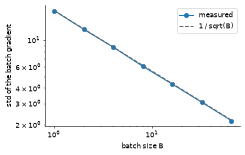

In [14]:
w0 = np.zeros(2)
per_example = X_std * (X_std @ w0 - score)[:, None]          # one gradient per example
full = per_example.mean(axis=0)
r = np.random.default_rng(3)
sizes = [1, 2, 4, 8, 16, 32, 64]
stds, means = [], []
for B in sizes:
    est = np.array([per_example[r.choice(n, B)].mean(axis=0) for _ in range(4000)])
    stds.append(est[:, 0].std()); means.append(est[:, 0].mean())
print("full gradient (first coordinate):", round(full[0], 3))
for B, m_, s_ in zip(sizes, means, stds):
    print(f"B = {B:3d}: mean of estimates {m_:8.3f}, standard deviation {s_:6.3f}, std * sqrt(B) = {s_ * np.sqrt(B):6.3f}")
plt.figure(figsize=(5, 3.2))
plt.loglog(sizes, stds, "o-", color=BLUE, label="measured")
plt.loglog(sizes, stds[0] / np.sqrt(sizes), "--", color="0.4", label="1 / sqrt(B)")
plt.xlabel("batch size B"); plt.ylabel("std of the batch gradient"); plt.legend(); plt.tight_layout()

The last column is nearly constant, which is the $1/\sqrt{B}$ law (batches are drawn with replacement here, so the examples in a batch are independent). Quadrupling the batch halves the noise and quadruples the cost.

## 11. Learning-rate schedules

Four schedules over $100$ steps, and then their effect on SGD (one example per update, $30$ epochs). With a fixed $\eta$ the loss stops improving at a noise floor. A schedule that shrinks $\eta$ lets it settle closer to the minimum.

cosine at t = 0, 25, 50, 75, 100: [0.1    0.0854 0.05   0.0146 0.    ]


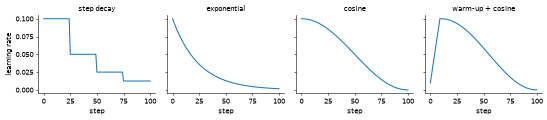

In [15]:
T = 100
t = np.arange(T + 1)
eta0 = 0.1
sched = {
    "step decay": eta0 * 0.5 ** np.minimum(t // 25, 3),
    "exponential": eta0 * 0.96 ** t,
    "cosine": 0.5 * eta0 * (1 + np.cos(np.pi * t / T)),
    "warm-up + cosine": np.where(t < 10, eta0 * (t + 1) / 10, 0.5 * eta0 * (1 + np.cos(np.pi * (t - 10) / (T - 10)))),
}
fig, axs = plt.subplots(1, 4, figsize=(11, 2.5), sharey=True)
for ax, (k, v) in zip(axs, sched.items()):
    ax.plot(t, v, color=BLUE); ax.set_title(k); ax.set_xlabel("step")
axs[0].set_ylabel("learning rate"); fig.tight_layout()
print("cosine at t = 0, 25, 50, 75, 100:", np.round(sched["cosine"][[0, 25, 50, 75, 100]], 4))

constant 0.1             average excess loss after 30 epochs: 2.76e-02
constant 0.01            average excess loss after 30 epochs: 2.61e-04
cosine from 0.1          average excess loss after 30 epochs: 2.31e-05
0.1 / (1 + 0.5 epoch)    average excess loss after 30 epochs: 7.37e-05


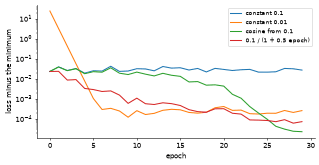

In [16]:
def sgd_loss_curve(schedule, epochs=30, seeds=20):
    # excess loss after each epoch, averaged over several shuffles to tame the noise
    total = np.zeros(epochs)
    for seed in range(seeds):
        r = np.random.default_rng(seed)
        w = np.zeros(2)
        for e in range(epochs):
            for i in r.permutation(n):
                w = w - schedule(e) * grad_mse(w, X_std[[i]], score[[i]])
            total[e] += mse(w, X_std) - mse(w_star, X_std)
    return total / seeds

runs = {
    "constant 0.1": sgd_loss_curve(lambda e: 0.1),
    "constant 0.01": sgd_loss_curve(lambda e: 0.01),
    "cosine from 0.1": sgd_loss_curve(lambda e: 0.5 * 0.1 * (1 + np.cos(np.pi * e / 30))),
    "0.1 / (1 + 0.5 epoch)": sgd_loss_curve(lambda e: 0.1 / (1 + 0.5 * e)),
}
plt.figure(figsize=(6.5, 3.4))
for k, v in runs.items():
    plt.semilogy(v + 1e-9, label=k)
    print(f"{k:24s} average excess loss after 30 epochs: {v[-1]:.2e}")
plt.xlabel("epoch"); plt.ylabel("loss minus the minimum"); plt.legend(fontsize=8); plt.tight_layout()

The constant steps level off at a floor that depends on $\eta$ (smaller $\eta$, lower floor, slower start). The decaying schedules begin fast and keep falling, so they end well below the constant-$0.1$ floor.

## 12. Momentum

Momentum keeps a velocity: $\mathbf{v} \leftarrow \beta\mathbf{v} + \mathbf{g}$ and $\mathbf{x} \leftarrow \mathbf{x} - \eta\mathbf{v}$. The class below also has the Nesterov variant, which computes the gradient at the look-ahead point (here in the usual rearranged form $\mathbf{g} + \beta\mathbf{v}$, after $\mathbf{v}$ is updated). With $\beta = 0$ it is plain gradient descent.

momentum on x^2: [ 4.      3.2     1.84    0.248  -1.2344]  plain GD: [4.    3.2   2.56  2.048]


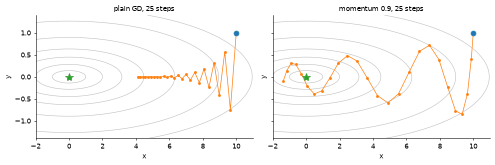

In [17]:
class SGD:
    # Plain gradient descent, or momentum / Nesterov momentum when momentum > 0.
    def __init__(self, lr=0.1, momentum=0.0, nesterov=False):
        self.lr, self.beta, self.nesterov, self.v = lr, momentum, nesterov, None
    def step(self, w, g):
        self.v = g if self.v is None else self.beta * self.v + g
        d = g + self.beta * self.v if self.nesterov else self.v
        return w - self.lr * d


def run_optimizer(opt, grad, w0, steps):
    w = np.array(w0, dtype=float); path = [w.copy()]
    for _ in range(steps):
        w = opt.step(w, grad(w)); path.append(w.copy())
    return np.array(path)

# the hand example of the README: f = x^2, eta = 0.1, beta = 0.9, start at 4
hand = run_optimizer(SGD(0.1, 0.9), lambda x: 2 * x, [4.0], 4)[:, 0]
print("momentum on x^2:", np.round(hand, 4), " plain GD:", np.round(run_optimizer(SGD(0.1), lambda x: 2 * x, [4.0], 3)[:, 0], 3))

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True, sharey=True)
lv = [0.5, 2, 5, 10, 20, 40, 60]
contour_path(axs[0], f_vall, run_optimizer(SGD(0.035), g_vall, [10, 1], 25), (-2, 11), (-1.4, 1.4), lv); axs[0].set_title("plain GD, 25 steps")
contour_path(axs[1], f_vall, run_optimizer(SGD(0.012, 0.9), g_vall, [10, 1], 25), (-2, 11), (-1.4, 1.4), lv); axs[1].set_title("momentum 0.9, 25 steps")
fig.tight_layout()

In [18]:
def steps_to(opt, grad, f, w0, tol=1e-6, cap=3000):
    w = np.array(w0, dtype=float)
    for k in range(cap):
        if f(w) < tol:
            return k
        w = opt.step(w, grad(w))
        if not np.all(np.isfinite(w)) or f(w) > 1e12:
            return None
    return None

print("valley kappa = 50, start (10, 1), steps until f < 1e-6")
print("plain GD, eta = 0.039:", steps_to(SGD(0.039), g_vall, f_vall, [10, 1]))
for lr in [0.005, 0.01, 0.02]:
    print(f"momentum 0.9, eta = {lr}:", steps_to(SGD(lr, 0.9), g_vall, f_vall, [10, 1]),
          f"  Nesterov: {steps_to(SGD(lr, 0.9, True), g_vall, f_vall, [10, 1])}")
lam_min, lam_max = 1.0, 50.0
eta_hb = 4 / (np.sqrt(lam_max) + np.sqrt(lam_min)) ** 2
beta_hb = ((np.sqrt(50) - 1) / (np.sqrt(50) + 1)) ** 2
print(f"tuned heavy ball (eta = {eta_hb:.3f}, beta = {beta_hb:.3f}):", steps_to(SGD(eta_hb, beta_hb), g_vall, f_vall, [10, 1]))
print("stability limit eta * lambda < 2 (1 + beta) with beta = 0.9 gives eta <", 2 * 1.9 / 50)
print("eta = 0.07:", steps_to(SGD(0.07, 0.9), g_vall, f_vall, [10, 1]), "  eta = 0.08:", steps_to(SGD(0.08, 0.9), g_vall, f_vall, [10, 1]))

valley kappa = 50, start (10, 1), steps until f < 1e-6
plain GD, eta = 0.039: 223
momentum 0.9, eta = 0.005: 165   Nesterov: 116
momentum 0.9, eta = 0.01: 162   Nesterov: 98
momentum 0.9, eta = 0.02: 153   Nesterov: 109
tuned heavy ball (eta = 0.061, beta = 0.566): 46
stability limit eta * lambda < 2 (1 + beta) with beta = 0.9 gives eta < 0.076
eta = 0.07: 160   eta = 0.08: None


Momentum cuts the step count and, when tuned for the valley, brings the work down from roughly $\kappa$ to roughly $\sqrt{\kappa}$ steps. It also tolerates a larger $\eta$ than plain descent. The path swings, though: a heavy ball overshoots.

## 13. AdaGrad stalls, RMSProp does not

AdaGrad divides by the square root of the running **sum** of squared gradients, which only grows, so the effective step keeps shrinking. RMSProp divides by a running **average**, which forgets old gradients.

In [19]:
class AdaGrad:
    def __init__(self, lr=0.1, eps=1e-8):
        self.lr, self.eps, self.G = lr, eps, 0.0
    def step(self, w, g):
        self.G = self.G + g ** 2
        return w - self.lr * g / (np.sqrt(self.G) + self.eps)


class RMSProp:
    def __init__(self, lr=0.01, rho=0.9, eps=1e-8):
        self.lr, self.rho, self.eps, self.s = lr, rho, eps, 0.0
    def step(self, w, g):
        self.s = self.rho * self.s + (1 - self.rho) * g ** 2
        return w - self.lr * g / (np.sqrt(self.s) + self.eps)

g_const = 2.0
G = s = 0.0
print("constant gradient 2: step / eta")
for t in range(1, 6):
    G += g_const ** 2; s = 0.9 * s + 0.1 * g_const ** 2
    print(f"t = {t}: AdaGrad {g_const / np.sqrt(G):.3f}   RMSProp {g_const / np.sqrt(s):.3f}")

constant gradient 2: step / eta
t = 1: AdaGrad 1.000   RMSProp 3.162
t = 2: AdaGrad 0.707   RMSProp 2.294
t = 3: AdaGrad 0.577   RMSProp 1.921
t = 4: AdaGrad 0.500   RMSProp 1.705
t = 5: AdaGrad 0.447   RMSProp 1.563


AdaGrad lr 0.5   x after 400 steps =   17.799
RMSProp lr 0.5   x after 400 steps =   50.000
RMSProp lr 0.05  x after 400 steps =   20.233


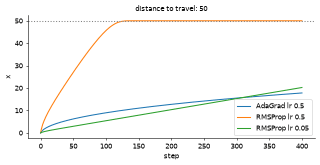

In [20]:
# a long, gently sloped linear problem: f(x) = 0.5 * (x - 50)^2 in one variable, far from the start
f_far = lambda w: 0.5 * np.sum((w - 50.0) ** 2)
g_far = lambda w: w - 50.0
res = {}
for name, opt in [("AdaGrad lr 0.5", AdaGrad(0.5)), ("RMSProp lr 0.5", RMSProp(0.5)), ("RMSProp lr 0.05", RMSProp(0.05))]:
    p = run_optimizer(opt, g_far, [0.0], 400)[:, 0]
    res[name] = p
    print(f"{name:16s} x after 400 steps = {p[-1]:8.3f}")
plt.figure(figsize=(6.5, 3.4))
for k, v in res.items():
    plt.plot(v, label=k)
plt.axhline(50, color="0.5", ls=":"); plt.xlabel("step"); plt.ylabel("x"); plt.legend(); plt.title("distance to travel: 50")
plt.tight_layout()

AdaGrad's steps shrink like $1/\sqrt{t}$, so on a long journey it slows down well before it arrives. RMSProp keeps a steady step of about $\eta$ per coordinate and arrives quickly (with a constant $\eta$ it can jitter near the target, which a decay would remove).

## 14. Adam, and why the bias correction matters

Adam keeps $\mathbf{m}$ (average of gradients) and $\mathbf{v}$ (average of squared gradients), both starting at $0$. Early on they are biased toward $0$. Dividing by $1-\beta_1^t$ and $1-\beta_2^t$ undoes that. With a constant gradient $g = 2$ the corrected step is exactly $\eta$ from the first step on.

In [21]:
class Adam:
    def __init__(self, lr=0.001, b1=0.9, b2=0.999, eps=1e-8, correct=True):
        self.lr, self.b1, self.b2, self.eps, self.correct = lr, b1, b2, eps, correct
        self.m, self.v, self.t = 0.0, 0.0, 0
    def step(self, w, g):
        self.t += 1
        self.m = self.b1 * self.m + (1 - self.b1) * g
        self.v = self.b2 * self.v + (1 - self.b2) * g ** 2
        m_hat = self.m / (1 - self.b1 ** self.t) if self.correct else self.m
        v_hat = self.v / (1 - self.b2 ** self.t) if self.correct else self.v
        return w - self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

on, off = Adam(lr=1.0), Adam(lr=1.0, correct=False)
print("constant gradient 2, step / eta")
print("step  corrected  uncorrected")
w_on = w_off = 0.0
for t in range(1, 7):
    new_on, new_off = on.step(w_on, 2.0), off.step(w_off, 2.0)
    print(f"{t:4d}  {w_on - new_on:9.3f}  {w_off - new_off:11.3f}")
    w_on, w_off = new_on, new_off
print("by hand, step 1: m = 0.2, v = 0.004, uncorrected 0.2 / sqrt(0.004) =", round(0.2 / np.sqrt(0.004), 3))

constant gradient 2, step / eta
step  corrected  uncorrected
   1      1.000        3.162
   2      1.000        4.250
   3      1.000        4.950
   4      1.000        5.442
   5      1.000        5.797
   6      1.000        6.057
by hand, step 1: m = 0.2, v = 0.004, uncorrected 0.2 / sqrt(0.004) = 3.162


largest of the first 10 steps (in units of eta): corrected 1.0  uncorrected 6.42


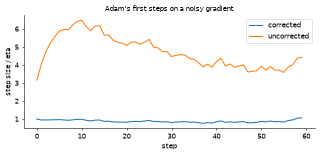

In [22]:
# the first 60 steps on a noisy gradient: the corrected version takes steps of about eta from the start
rng14 = np.random.default_rng(5)
noisy = 1.0 + 0.5 * rng14.normal(size=60)               # a gradient that is 1 on average
steps = {}
for label, corr in [("corrected", True), ("uncorrected", False)]:
    o = Adam(lr=1.0, correct=corr); w = 0.0; sizes = []
    for g in noisy:
        w_new = o.step(w, g); sizes.append(w - w_new); w = w_new
    steps[label] = np.array(sizes)
plt.figure(figsize=(6.5, 3.2))
for k, v in steps.items():
    plt.plot(v, label=k)
plt.xlabel("step"); plt.ylabel("step size / eta"); plt.legend(); plt.title("Adam's first steps on a noisy gradient")
plt.tight_layout()
print("largest of the first 10 steps (in units of eta): corrected", steps["corrected"][:10].max().round(2), " uncorrected", steps["uncorrected"][:10].max().round(2))

Without the correction the first steps are several times too large (with $\beta_2 = 0.999$ the second average starts almost empty). After a few hundred steps both versions agree, since $\beta^t \to 0$.

## 15. All the optimisers on one problem

The raw (badly scaled) regression has $\kappa \approx 174$. We run every optimiser full-batch for $150$ steps with a hand-picked learning rate and plot the loss above its minimum. The rates are reasonable starting points, not a careful tuning, so read the picture as a pattern.

GD (0.04)              excess loss after 150 steps: 9.39e-02
momentum (0.02, 0.9)   excess loss after 150 steps: 4.50e-06
Nesterov (0.02, 0.9)   excess loss after 150 steps: 1.33e-07
AdaGrad (1.0)          excess loss after 150 steps: 1.59e-02
RMSProp (0.1)          excess loss after 150 steps: 3.21e-02
Adam (0.5)             excess loss after 150 steps: 2.14e-05


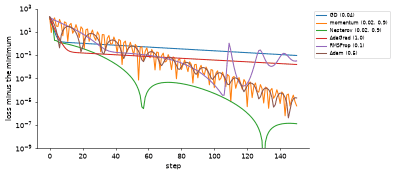

In [23]:
g_raw = lambda w: grad_mse(w, X_raw, score)
loss_raw = lambda w: mse(w, X_raw)
best_raw = loss_raw(np.linalg.lstsq(X_raw, score, rcond=None)[0])
contenders = {
    "GD (0.04)": SGD(0.04),
    "momentum (0.02, 0.9)": SGD(0.02, 0.9),
    "Nesterov (0.02, 0.9)": SGD(0.02, 0.9, True),
    "AdaGrad (1.0)": AdaGrad(1.0),
    "RMSProp (0.1)": RMSProp(0.1),
    "Adam (0.5)": Adam(0.5),
}
plt.figure(figsize=(8, 3.6))
for name, opt in contenders.items():
    path = run_optimizer(opt, g_raw, [0.0, 0.0], 150)
    gap = np.array([loss_raw(w) for w in path]) - best_raw
    plt.semilogy(np.maximum(gap, 1e-12), label=name)
    print(f"{name:22s} excess loss after 150 steps: {gap[-1]:.2e}")
plt.xlabel("step"); plt.ylabel("loss minus the minimum"); plt.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.ylim(1e-9, 1e3); plt.tight_layout()

Plain descent and AdaGrad (whose steps keep shrinking) are slowest here. Momentum, Nesterov, and Adam reach the minimum region far sooner, and they oscillate around it, because a constant $\eta$ never lets them settle. RMSProp with this $\eta$ also oscillates and is still above the others. Which one wins depends on the problem and on the tuning, so read the picture as a pattern.

## 16. Logistic regression with mini-batch Adam

Two invented clouds of $100$ points each, one centred at $(-1, -1)$ and one at $(1.5, 1)$. The model is $p = \sigma(\mathbf{w}\cdot\mathbf{x} + b)$ with the average log loss. The gradient is $\frac1n X^\top(\mathbf{p} - \mathbf{y})$ for the weights and $\frac1n\sum(p_i - y_i)$ for the bias. We train with `Adam` on mini-batches of $32$ and compare with full-batch gradient descent.

In [24]:
rng = np.random.default_rng(7)
Xc = np.vstack([rng.normal([-1.0, -1.0], 1.0, size=(100, 2)), rng.normal([1.5, 1.0], 1.0, size=(100, 2))])
yc = np.r_[np.zeros(100), np.ones(100)]
sigmoid = lambda z: 1 / (1 + np.exp(-z))

def log_loss(theta, X, y):                                 # theta = (w1, w2, b)
    p = sigmoid(X @ theta[:2] + theta[2])
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def log_grad(theta, X, y):
    r = sigmoid(X @ theta[:2] + theta[2]) - y              # prediction minus label
    return np.r_[X.T @ r, r.sum()] / len(y)

theta, opt, r2 = np.zeros(3), Adam(lr=0.05), np.random.default_rng(0)
curve = [log_loss(theta, Xc, yc)]
for epoch in range(30):
    idx = r2.permutation(200)
    for s in range(0, 200, 32):
        b = idx[s:s + 32]
        theta = opt.step(theta, log_grad(theta, Xc[b], yc[b]))
    curve.append(log_loss(theta, Xc, yc))
acc = np.mean((sigmoid(Xc @ theta[:2] + theta[2]) > 0.5) == yc)
print("mini-batch Adam:", theta.round(3), " loss", round(log_loss(theta, Xc, yc), 4), " accuracy", acc)

th_gd = np.zeros(3); curve_gd = [log_loss(th_gd, Xc, yc)]
for _ in range(500):
    th_gd = th_gd - 0.5 * log_grad(th_gd, Xc, yc); curve_gd.append(log_loss(th_gd, Xc, yc))
print("full-batch GD, 500 steps:", th_gd.round(3), " loss", round(log_loss(th_gd, Xc, yc), 4))
print("gradient norm at the Adam solution:", np.linalg.norm(log_grad(theta, Xc, yc)).round(4))

mini-batch Adam: [2.539 1.819 0.232]  loss 0.1156  accuracy 0.945
full-batch GD, 500 steps: [2.97  2.004 0.233]  loss 0.1138
gradient norm at the Adam solution: 0.0076


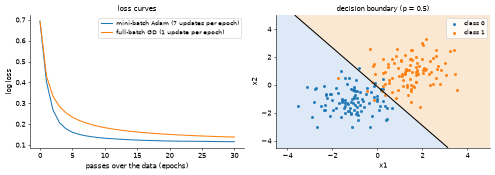

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(curve, label="mini-batch Adam (7 updates per epoch)"); axs[0].plot(curve_gd[:31], label="full-batch GD (1 update per epoch)")
axs[0].set_xlabel("passes over the data (epochs)"); axs[0].set_ylabel("log loss"); axs[0].legend(fontsize=8); axs[0].set_title("loss curves")
g_ = np.linspace(-4.5, 5, 200); X1, X2 = np.meshgrid(g_, g_)
P = sigmoid(theta[0] * X1 + theta[1] * X2 + theta[2])
axs[1].contourf(X1, X2, P, levels=[0, 0.5, 1], colors=["#d6e4f5", "#fbe3c9"], alpha=0.8)
axs[1].contour(X1, X2, P, levels=[0.5], colors="k")
axs[1].scatter(*Xc[yc == 0].T, s=10, color=BLUE, label="class 0"); axs[1].scatter(*Xc[yc == 1].T, s=10, color=ORANGE, label="class 1")
axs[1].legend(fontsize=8); axs[1].set_title("decision boundary (p = 0.5)"); axs[1].set_xlabel("x1"); axs[1].set_ylabel("x2")
fig.tight_layout()

The loss curves both flatten out and the boundary separates the clouds, apart from the points where they overlap. The optimiser changes the road taken, not the destination.

## 17. Checking the optimiser classes against the hand numbers

A good habit: before using an optimiser, reproduce a case you can do on paper. The classes `SGD`, `AdaGrad`, `RMSProp`, and `Adam` above hold their own state and have one method, `step(w, g)`.

In [26]:
# momentum, README section 7: f = x^2, eta = 0.1, beta = 0.9, start at 4
assert np.allclose(hand, [4, 3.2, 1.84, 0.248, -1.2344])
# Adam's first step, README section 9: g = 2 gives a step of exactly eta (up to eps)
first = Adam(lr=0.1).step(np.array([1.0, 1.0]), np.array([2.0, 0.02]))
assert np.allclose(1.0 - first, 0.1, atol=1e-6)
# AdaGrad and RMSProp first steps with g = 2, divided by eta
assert np.isclose(2.0 / (np.sqrt(4.0) + 1e-8), 1.0) and np.isclose(2.0 / np.sqrt(0.4), 3.1623, atol=1e-4)
a1 = AdaGrad(lr=1.0).step(np.array([0.0]), np.array([2.0]))
r1 = RMSProp(lr=1.0).step(np.array([0.0]), np.array([2.0]))
print("AdaGrad first step:", -a1, " RMSProp first step:", -r1)
# with momentum 0 the SGD class is plain gradient descent
assert np.allclose(run_optimizer(SGD(0.1), g1, [0.0], 3)[:, 0], [0, 0.6, 1.08, 1.464])
print("all hand checks passed")

# a two-parameter model (the regression on raw inputs) trained with each class
for name, mk in [("GD", lambda: SGD(0.04)), ("momentum", lambda: SGD(0.02, 0.9)), ("Adam", lambda: Adam(0.5))]:
    w = run_optimizer(mk(), g_raw, [0.0, 0.0], 100)[-1]
    print(f"{name:9s} 100 steps: w = {w.round(3)}, loss = {loss_raw(w):.4f}   (least squares: {best_raw:.4f})")

AdaGrad first step: [1.]  RMSProp first step: [3.1623]
all hand checks passed
GD        100 steps: w = [2.689 2.573], loss = 0.5370   (least squares: 0.3008)
momentum  100 steps: w = [2.484 4.017], loss = 0.3010   (least squares: 0.3008)
Adam      100 steps: w = [2.506 3.92 ], loss = 0.3021   (least squares: 0.3008)


## 18. Gradient check

Before trusting a gradient you wrote by hand, compare it with a centered finite difference (`num_grad`, the same function as in [multivariable calculus](../multivariable-calculus/README.md)). The relative error should be around $10^{-7}$ or below. A deliberately broken gradient shows what a bug looks like.

In [27]:
rel_err = lambda a, b: np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b))
tp = np.array([0.3, -0.2, 0.1])
exact = log_grad(tp, Xc, yc)
approx = num_grad(lambda q: log_loss(q, Xc, yc), tp)
buggy = exact.copy(); buggy[2] *= 2                       # bias gradient twice too big
forgot_mean = exact * len(yc)                             # forgot to divide by n
print("exact  :", exact)
print("numeric:", approx)
print("correct gradient      :", rel_err(exact, approx))
print("bias gradient doubled :", rel_err(buggy, approx))
print("forgot to divide by n :", rel_err(forgot_mean, approx))
print("check passes for the correct one:", rel_err(exact, approx) < 1e-7, " fails for the buggy ones:", rel_err(buggy, approx) > 1e-4 and rel_err(forgot_mean, approx) > 1e-4)

p = np.array([1.0, 2.0])
print("regression gradient on raw inputs:", rel_err(grad_mse(p, X_raw, score), num_grad(lambda q: mse(q, X_raw), p)))

exact  : [-0.5246 -0.501   0.0389]
numeric: [-0.5246 -0.501   0.0389]
correct gradient      : 7.204129942080503e-12
bias gradient doubled : 0.026721664444527893
forgot to divide by n : 0.9900497512436499
check passes for the correct one: True  fails for the buggy ones: True
regression gradient on raw inputs: 2.163493045107618e-12


## What you practised

You ran gradient descent by hand and in code, saw the learning-rate limit $2/\lambda_{\max}$ and the zig-zag of a narrow valley, fixed it with feature scaling, and compared batch, stochastic, and mini-batch updates and their noise. You added schedules, momentum, AdaGrad, RMSProp, and Adam with bias correction, compared them on one problem, trained a logistic regression, and checked your own classes and gradients against known answers. Next come Newton and quasi-Newton methods, which use the Hessian to choose both the direction and the step.